# Bollerslev, Tauchen & Zhou (2009) — replication findings

Arthur Teman, M1 QEF (HEC Paris). Code: github.com/arthur-teman/btz2009-replication, specs 001–006.

Conventions used everywhere below: S&P 500 index (^GSPC), VIX from Yahoo, realized variance from daily log returns (the paper uses 5-minute returns), variances in monthly percent squared (VIX²/12), returns in annualized percent, risk-free rate = previous month's 3-month T-bill. The main statistic is the Hodrick (1992) 1B t-statistic, as in the paper. Every number in the text is asserted against the results files when the notebook runs.

In [1]:
import shutil
import time
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

T0 = time.perf_counter()
ROOT = Path.cwd()
RES = ROOT / "results"
OUT = RES / "006-findings"
assert (RES / "001-baseline-1990").is_dir(), "Run the notebook from the repository root"
OUT.mkdir(parents=True, exist_ok=True)

ASSERTIONS: list[dict] = []

# Claim numbers that the results do not reproduce. The claim text stays verbatim;
# each entry holds the value the results give, so the notebook still stops if
# either the claim or the results change.
KNOWN_DEVIATIONS = {
    ("F2", "t1B ratio, h = 6"): 0.86,
    ("F2", "sqrt adj. R² ratio, h = 1"): 0.91,
    ("F2", "sqrt adj. R² ratio, h = 3"): 0.81,
    ("F2", "daily returns a month"): 21,
    ("F2", "five-minute returns a month"): 1600,
}


def check(finding, label, value, claimed, decimals):
    """Assert a number quoted in a claim to ±0.5 in its last printed digit."""
    value = float(value)
    tol = 0.5 * 10.0 ** (-decimals) + 1e-9
    matches = abs(value - claimed) <= tol
    known = KNOWN_DEVIATIONS.get((finding, label))
    if known is None:
        assert matches, f"{finding} {label}: results give {value:.6g}, the claim says {claimed}"
        status = "pass"
    else:
        assert not matches, f"{finding} {label}: listed as a deviation but now matches the claim"
        assert abs(value - known) <= tol, f"{finding} {label}: {value:.6g} is not the recorded value {known}"
        status = "DEVIATION"
    shown = f"{value:.{max(decimals + 2, 0)}f}"
    claim_text = f"{claimed:.{max(decimals, 0)}f}"
    ASSERTIONS.append({"finding": finding, "assertion": label, "claim": claim_text, "results": shown, "status": status})
    print(f"{status:9s}  {finding}  {label}: claim {claimed}, results {shown}")


def check_that(finding, label, condition, detail):
    """Assert a qualitative statement of a claim; `detail` records the values behind it."""
    assert bool(condition), f"{finding} {label}: {detail}"
    ASSERTIONS.append({"finding": finding, "assertion": label, "claim": "holds", "results": detail, "status": "pass"})
    print(f"{'pass':9s}  {finding}  {label}: {detail}")


def styled(df, coef=(), pval=(), ints=()):
    """2 decimals; 3 for coefficients and p-values; integers for counts."""
    fmt = {}
    for col in df.columns:
        if col in ints:
            fmt[col] = "{:.0f}"
        elif col in coef or col in pval:
            fmt[col] = "{:.3f}"
        elif pd.api.types.is_numeric_dtype(df[col]):
            fmt[col] = "{:.2f}"
    return df.style.format(fmt, na_rep="—").hide(axis="index")


def show_figure(src: Path) -> Path:
    dst = OUT / src.name
    shutil.copyfile(src, dst)
    display(Image(filename=str(dst)))
    return dst


def adjusted_r2(r2_pct, n):
    return 100.0 * (1.0 - (1.0 - r2_pct / 100.0) * (n - 1) / (n - 2))

## F1 — Table 2 is reproduced.

> On the paper's sample (January 1990 – December 2007), the variance risk premium coefficients are within 0.05 of BTZ Table 2 at every horizon up to 15 months (h = 3: 0.42 vs 0.47). Predictability is hump-shaped and peaks at the quarterly horizon, both for the coefficient and the Hodrick t-statistic (h = 3: 2.22 vs 2.86 in the paper). From 18 months on, neither the paper's estimates nor mine are significant.

**Source:** spec 006 Part A (`src/table2_full.py`), commit `006 full Table 2 in the paper's statistics and findings notebook`; `results/006-table2-full/table2_full.csv`, `results/006-table2-full/fig_table2_vs_btz.png`.

In [2]:
t2 = pd.read_csv(RES / "006-table2-full" / "table2_full.csv").set_index("h")
assert list(t2.index) == [1, 3, 6, 9, 12, 15, 18, 24]

gap_15 = (t2["coef"] - t2["BTZ_coef"]).abs().loc[lambda s: s.index <= 15]
check_that(
    "F1", "max |coef − BTZ| ≤ 0.05 for h ≤ 15 (±0.005)", gap_15.max() <= 0.05 + 0.005,
    f"max {gap_15.max():.4f} at h = {gap_15.idxmax()}",
)
check("F1", "coef, h = 3", t2.loc[3, "coef"], 0.42, 2)
check("F1", "BTZ coef, h = 3", t2.loc[3, "BTZ_coef"], 0.47, 2)
check_that(
    "F1", "coefficient peaks at h = 3 (mine and BTZ)",
    t2["coef"].idxmax() == 3 and t2["BTZ_coef"].idxmax() == 3,
    f"argmax mine h = {t2['coef'].idxmax()}, BTZ h = {t2['BTZ_coef'].idxmax()}",
)
check_that(
    "F1", "Hodrick t peaks at h = 3 (mine and BTZ)",
    t2["t1B_coef"].idxmax() == 3 and t2["BTZ_t_coef"].idxmax() == 3,
    f"argmax mine h = {t2['t1B_coef'].idxmax()}, BTZ h = {t2['BTZ_t_coef'].idxmax()}",
)
check("F1", "Hodrick t, h = 3", t2.loc[3, "t1B_coef"], 2.22, 2)
check("F1", "BTZ Hodrick t, h = 3", t2.loc[3, "BTZ_t_coef"], 2.86, 2)
late = t2.loc[t2.index >= 18]
check_that(
    "F1", "no Hodrick |t| above 1.96 for h ≥ 18 (mine and BTZ)",
    (late["t1B_coef"].abs() < 1.96).all() and (late["BTZ_t_coef"].abs() < 1.96).all(),
    "mine " + ", ".join(f"{v:.2f}" for v in late["t1B_coef"])
    + "; BTZ " + ", ".join(f"{v:.2f}" for v in late["BTZ_t_coef"]),
)

pass       F1  max |coef − BTZ| ≤ 0.05 for h ≤ 15 (±0.005): max 0.0504 at h = 3
pass       F1  coef, h = 3: claim 0.42, results 0.4196
pass       F1  BTZ coef, h = 3: claim 0.47, results 0.4700
pass       F1  coefficient peaks at h = 3 (mine and BTZ): argmax mine h = 3, BTZ h = 3
pass       F1  Hodrick t peaks at h = 3 (mine and BTZ): argmax mine h = 3, BTZ h = 3
pass       F1  Hodrick t, h = 3: claim 2.22, results 2.2185
pass       F1  BTZ Hodrick t, h = 3: claim 2.86, results 2.8600
pass       F1  no Hodrick |t| above 1.96 for h ≥ 18 (mine and BTZ): mine 0.86, 0.56; BTZ 0.56, 0.11


In [3]:
table_f1 = t2.reset_index()[
    ["h", "const", "t1B_const", "BTZ_const", "BTZ_t_const", "coef", "t1B_coef", "tNW_coef",
     "BTZ_coef", "BTZ_t_coef", "R2", "adjR2", "BTZ_adjR2", "N"]
].rename(columns={
    "const": "constant", "t1B_const": "t1B constant", "BTZ_const": "BTZ constant",
    "BTZ_t_const": "BTZ t constant", "coef": "VRP coef", "t1B_coef": "t1B VRP", "tNW_coef": "tNW VRP",
    "BTZ_coef": "BTZ VRP coef", "BTZ_t_coef": "BTZ t VRP", "R2": "R² %", "adjR2": "adj. R² %",
    "BTZ_adjR2": "BTZ adj. R² %",
})
styled(table_f1, coef=["constant", "BTZ constant", "VRP coef", "BTZ VRP coef"], ints=["h", "N"])

h,constant,t1B constant,BTZ constant,BTZ t constant,VRP coef,t1B VRP,tNW VRP,BTZ VRP coef,BTZ t VRP,R² %,adj. R² %,BTZ adj. R² %,N
1,-0.562,-0.14,-0.550,-0.13,0.388,1.44,1.63,0.390,1.76,1.36,0.90,1.07,215
3,-0.872,-0.24,-2.080,-0.56,0.420,2.22,3.46,0.470,2.86,4.98,4.53,6.82,213
6,0.735,0.21,1.120,0.33,0.288,1.86,2.98,0.300,2.15,4.92,4.46,5.42,210
9,2.519,0.79,3.630,1.15,0.165,1.24,1.60,0.170,1.36,2.35,1.87,2.30,207
12,3.058,1.01,4.620,1.50,0.134,1.10,1.42,0.120,1.00,1.87,1.39,1.23,204
15,3.341,1.13,4.840,1.59,0.110,0.97,1.18,0.110,0.94,1.45,0.96,1.00,201
18,3.486,1.15,5.610,1.81,0.093,0.86,1.12,0.060,0.56,1.18,0.67,0.05,198
24,3.890,1.31,6.480,2.07,0.056,0.56,1.01,0.010,0.11,0.50,-0.02,-0.50,192


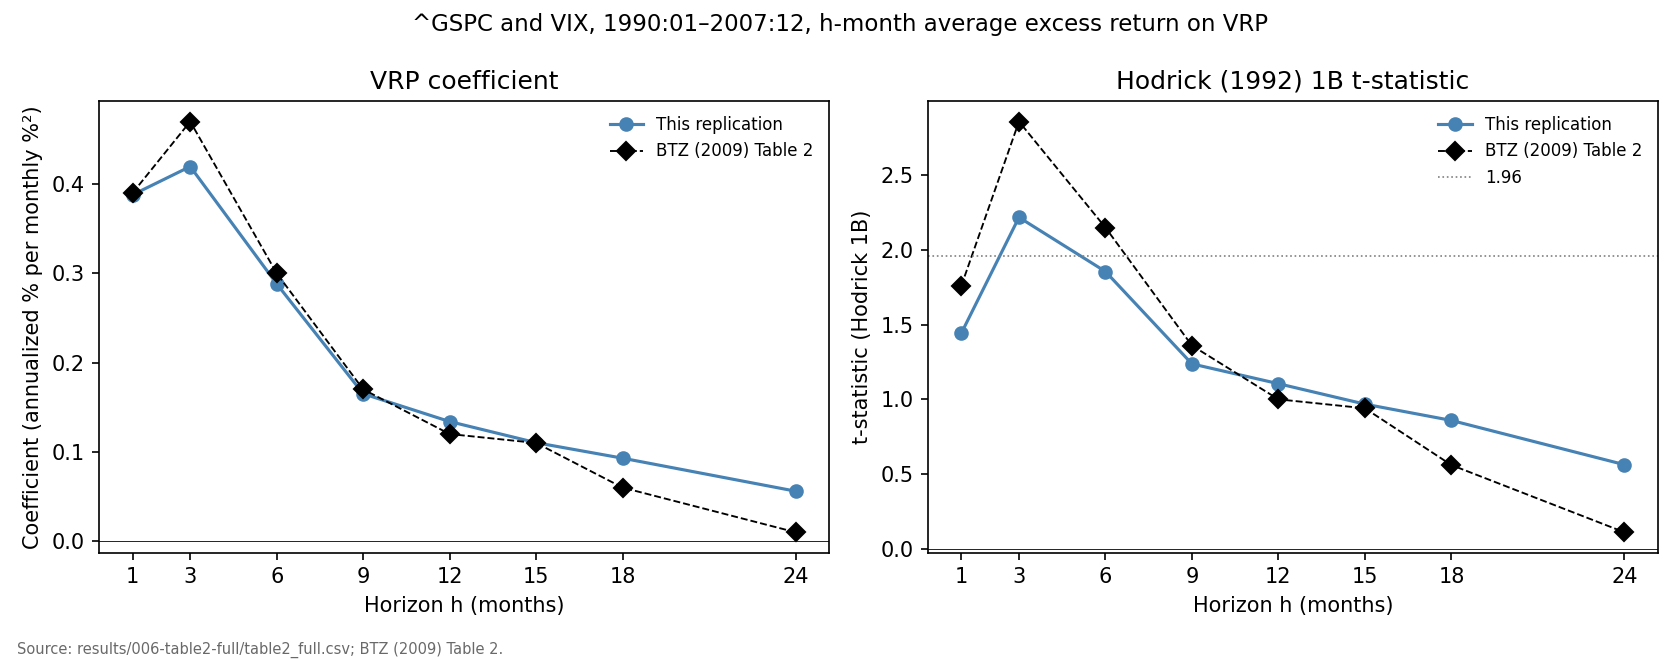

In [4]:
show_figure(RES / "006-table2-full" / "fig_table2_vs_btz.png");

*Figure F1.* Left: VRP coefficient (annualized % per monthly %²) against the horizon h (months). Right: Hodrick (1992) 1B t-statistic against h, with the 1.96 line. This replication (blue) and BTZ (2009) Table 2 (black). The constant and its t-statistic are in the table above. Source: `results/006-table2-full/table2_full.csv`, spec 006 Part A.

## F2 — The gap in t-statistics is the gap in fit, as expected from a noisier realized variance.

> My Hodrick t-statistics are below the paper's at short horizons (h = 1, 3, 6: ratios 0.82, 0.78, 0.87), and the adjusted R² is lower in the same proportion (square-root ratios 0.92, 0.82, 0.91). The slope is almost unchanged, so the gap comes from a noisier regressor: realized variance from 22 daily returns a month instead of about 1,700 five-minute returns. Over 1990–2007 my realized variance averages 20.8 against 33.2 for the implied variance (monthly percent squared), so the average premium is 12.4.

**Source:** spec 006 Part A, commit `006 full Table 2 in the paper's statistics and findings notebook`, `results/006-table2-full/table2_full.csv` (ratio columns); spec 001, commit `431406b`, `results/001-baseline-1990/table1_summary.csv`; trading days counted in `data/gspc_data.csv`.

In [5]:
ratio_table = pd.DataFrame({
    "ratio": ["t1B(mine) / t1B(BTZ)", "√(adj R²(mine) / adj R²(BTZ))"],
    "h = 1": [t2.loc[1, "ratio_t1B"], t2.loc[1, "ratio_sqrt_adjR2"]],
    "h = 3": [t2.loc[3, "ratio_t1B"], t2.loc[3, "ratio_sqrt_adjR2"]],
    "h = 6": [t2.loc[6, "ratio_t1B"], t2.loc[6, "ratio_sqrt_adjR2"]],
})
display(styled(ratio_table))  # the six ratios, reported before the assertions

ratio,h = 1,h = 3,h = 6
t1B(mine) / t1B(BTZ),0.82,0.78,0.86
√(adj R²(mine) / adj R²(BTZ)),0.91,0.81,0.91


In [6]:
for h, claimed in {1: 0.82, 3: 0.78, 6: 0.87}.items():
    check("F2", f"t1B ratio, h = {h}", t2.loc[h, "ratio_t1B"], claimed, 2)
for h, claimed in {1: 0.92, 3: 0.82, 6: 0.91}.items():
    check("F2", f"sqrt adj. R² ratio, h = {h}", t2.loc[h, "ratio_sqrt_adjR2"], claimed, 2)
check_that(
    "F2", "t-statistics below the paper's at h = 1, 3, 6",
    (t2.loc[[1, 3, 6], "ratio_t1B"] < 1).all(),
    ", ".join(f"{v:.3f}" for v in t2.loc[[1, 3, 6], "ratio_t1B"]),
)

gspc = pd.read_csv(ROOT / "data" / "gspc_data.csv", parse_dates=["Date"]).set_index("Date")["Close"]
daily = np.log(gspc.sort_index()).diff().dropna().loc["1990-01-01":"2007-12-31"]
per_month = daily.resample("ME").count()
assert len(per_month) == 216
check("F2", "daily returns a month", per_month.mean(), 22, 0)
# 6.5 trading hours = 78 five-minute returns a day.
check("F2", "five-minute returns a month", 78 * per_month.mean(), 1700, -2)

t1 = pd.read_csv(RES / "001-baseline-1990" / "table1_summary.csv")
moments = t1[t1["sample"] == "main"].set_index("variable")
assert int(moments.loc["RV", "n"]) == 216
check("F2", "mean RV 1990–2007", moments.loc["RV", "mean"], 20.8, 1)
check("F2", "mean IV 1990–2007", moments.loc["IV", "mean"], 33.2, 1)
check("F2", "mean VRP 1990–2007", moments.loc["VRP", "mean"], 12.4, 1)

pass       F2  t1B ratio, h = 1: claim 0.82, results 0.8196
pass       F2  t1B ratio, h = 3: claim 0.78, results 0.7757
DEVIATION  F2  t1B ratio, h = 6: claim 0.87, results 0.8631
DEVIATION  F2  sqrt adj. R² ratio, h = 1: claim 0.92, results 0.9149
DEVIATION  F2  sqrt adj. R² ratio, h = 3: claim 0.82, results 0.8149
pass       F2  sqrt adj. R² ratio, h = 6: claim 0.91, results 0.9075
pass       F2  t-statistics below the paper's at h = 1, 3, 6: 0.820, 0.776, 0.863
DEVIATION  F2  daily returns a month: claim 22, results 21.01
DEVIATION  F2  five-minute returns a month: claim 1700, results 1639
pass       F2  mean RV 1990–2007: claim 20.8, results 20.844
pass       F2  mean IV 1990–2007: claim 33.2, results 33.237
pass       F2  mean VRP 1990–2007: claim 12.4, results 12.394


In [7]:
styled(
    moments.loc[["IV", "RV", "VRP"], ["mean", "sd", "min", "max", "ar1", "n"]].reset_index(),
    ints=["n"],
)

variable,mean,sd,min,max,ar1,n
IV,33.24,23.74,9.05,163.39,0.79,216
RV,20.84,21.78,2.06,151.87,0.60,216
VRP,12.39,14.17,-66.37,65.70,0.17,216


*Table F2.* Monthly implied variance, realized variance and premium on 1990-01 – 2007-12, monthly percent squared (sd, min, max in the same units; ar1 is the first-order autocorrelation). Source: `results/001-baseline-1990/table1_summary.csv`, spec 001.

## F3 — Newey–West overstates significance; Hodrick does not.

> Under the null of no predictability, simulated by bootstrap, a nominal 5% Newey–West test with h−1 lags rejects 7.9% of the time on the paper's sample and 12.9% on 1990–2025 at h = 3, while the Hodrick test rejects 4.9% and 4.7%. The paper's choice of Hodrick standard errors is the right one; my earlier Newey–West t-statistics (3.46 at h = 3) overstated the evidence.

**Source:** specs 003 and 003a, commit `ec80a54`; `results/003-inference/table_size.csv` (iid columns) and `results/003-inference/table_inference.csv`, rows R-base and R-full.

In [8]:
size = pd.read_csv(RES / "003-inference" / "table_size.csv")
inference = pd.read_csv(RES / "003-inference" / "table_inference.csv")
s3 = size[size["h"] == 3].set_index("id")
i3 = inference[inference["h"] == 3].set_index("id")

check("F3", "NW size %, R-base h = 3", 100 * s3.loc["R-base", "size_NW_iid"], 7.9, 1)
check("F3", "NW size %, R-full h = 3", 100 * s3.loc["R-full", "size_NW_iid"], 12.9, 1)
check("F3", "Hodrick size %, R-base h = 3", 100 * s3.loc["R-base", "size_1B_iid"], 4.9, 1)
check("F3", "Hodrick size %, R-full h = 3", 100 * s3.loc["R-full", "size_1B_iid"], 4.7, 1)
check("F3", "NW t, R-base h = 3", i3.loc["R-base", "t_NW_hm1"], 3.46, 2)

pass       F3  NW size %, R-base h = 3: claim 7.9, results 7.880
pass       F3  NW size %, R-full h = 3: claim 12.9, results 12.940
pass       F3  Hodrick size %, R-base h = 3: claim 4.9, results 4.860
pass       F3  Hodrick size %, R-full h = 3: claim 4.7, results 4.680
pass       F3  NW t, R-base h = 3: claim 3.46, results 3.4554


In [9]:
size_f3 = size[size["id"].isin(["R-base", "R-full"])].copy()
for col in ["size_NW_iid", "size_1B_iid", "size_NW_wild", "size_1B_wild"]:
    size_f3[col] = 100 * size_f3[col]
size_f3 = size_f3.rename(columns={
    "size_NW_iid": "NW iid %", "size_1B_iid": "Hodrick iid %",
    "size_NW_wild": "NW wild %", "size_1B_wild": "Hodrick wild %",
})
styled(size_f3, ints=["h"])

id,h,NW iid %,Hodrick iid %,NW wild %,Hodrick wild %
R-base,1,6.84,4.80,5.92,4.58
R-base,3,7.88,4.86,9.90,4.62
R-base,6,8.42,4.78,10.58,5.14
R-full,1,11.70,3.94,31.36,2.22
R-full,3,12.94,4.68,21.20,3.76
R-full,6,13.04,4.74,20.28,4.82


*Table F3.* Rejection rate (%) of a nominal 5% two-sided test (|t| > 1.96) across 5,000 bootstrap samples generated under no predictability. R-base is 1990–2007, R-full 1990–2025. Newey–West uses max(1, h−1) lags. The iid columns are the null bootstrap quoted in the claim; the wild columns are shown for reference. Source: `results/003-inference/table_size.csv`, spec 003a.

## F4 — The paper's result survives conservative inference.

> At h = 3 on 1990–2007, the bootstrap p-value of the Newey–West t is 0.002 (iid) and 0.007 (wild), and the Hodrick t is 2.22.

**Source:** spec 003a, commit `ec80a54`, `results/003-inference/table_inference.csv`, row R-base; figure from spec 003, commit `708a8f9`, `results/003-inference/fig_boot_h3.png`.

In [10]:
base = i3.loc["R-base"]
check("F4", "p NW iid, R-base h = 3", base["p_boot_NW_iid"], 0.002, 3)
check("F4", "p NW wild, R-base h = 3", base["p_boot_NW_wild"], 0.007, 3)
check("F4", "Hodrick t, R-base h = 3", base["t_1B"], 2.22, 2)

pass       F4  p NW iid, R-base h = 3: claim 0.002, results 0.00200
pass       F4  p NW wild, R-base h = 3: claim 0.007, results 0.00680
pass       F4  Hodrick t, R-base h = 3: claim 2.22, results 2.2185


In [11]:
cols = ["id", "h", "coef_B", "t_NW_hm1", "t_1B", "p_boot_NW_iid", "p_boot_NW_wild",
        "p_boot_1B_iid", "p_boot_1B_wild", "N"]
styled(
    inference.loc[inference["id"] == "R-base", cols],
    coef=["coef_B"], pval=["p_boot_NW_iid", "p_boot_NW_wild", "p_boot_1B_iid", "p_boot_1B_wild"],
    ints=["h", "N"],
)

id,h,coef_B,t_NW_hm1,t_1B,p_boot_NW_iid,p_boot_NW_wild,p_boot_1B_iid,p_boot_1B_wild,N
R-base,1,0.388,1.63,1.44,0.127,0.116,0.153,0.149,215
R-base,3,0.420,3.46,2.22,0.002,0.007,0.023,0.024,213
R-base,6,0.288,2.98,1.86,0.012,0.019,0.064,0.066,210


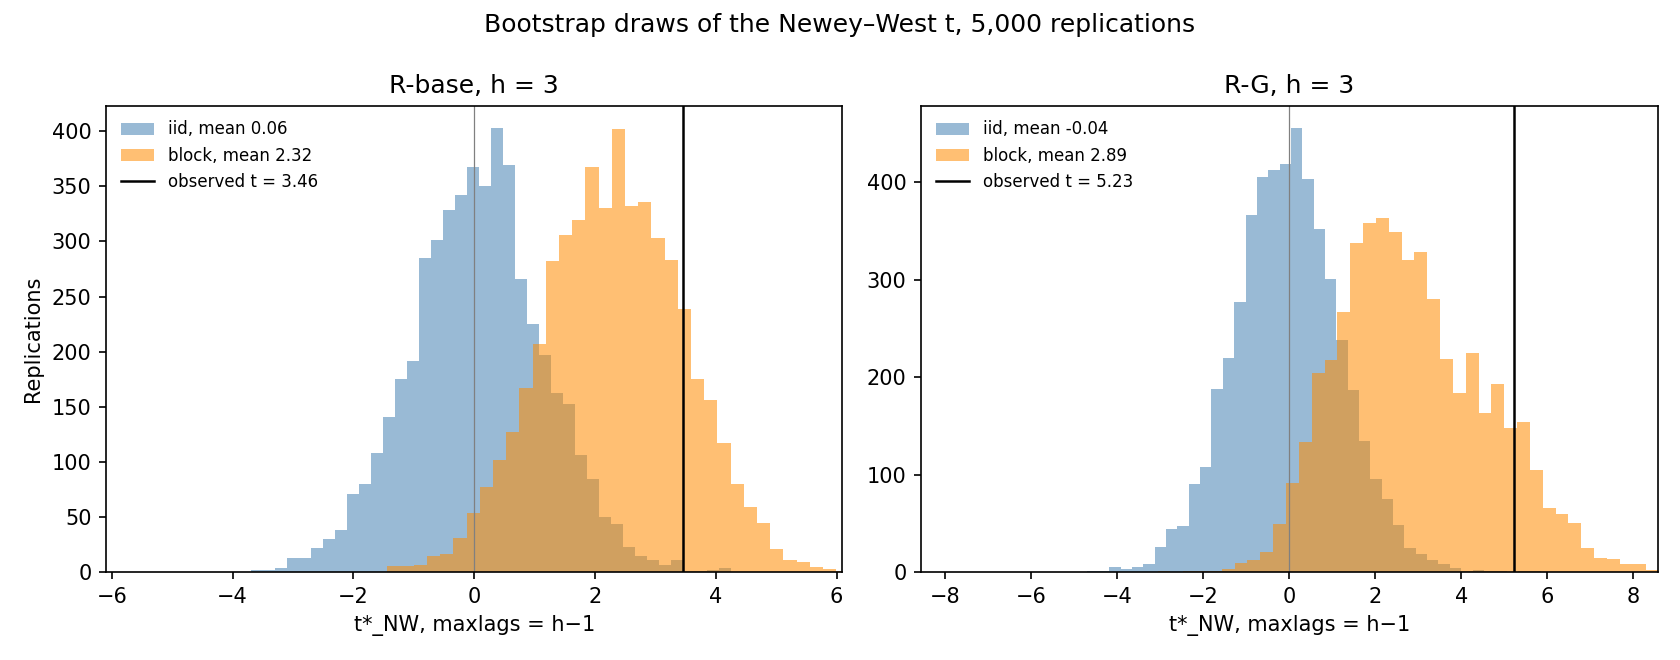

In [12]:
show_figure(RES / "003-inference" / "fig_boot_h3.png");

*Figure F4.* Bootstrap distribution of the Newey–West t-statistic (dimensionless, maxlags = h−1; vertical axis: number of replications out of 5,000) at h = 3, for R-base (1990–2007, left) and the forecast-based premium R-G (1995–2025, right); black line = observed t. The figure is copied from spec 003 and shows the iid and the stationary-block schemes; the wild scheme quoted in the claim replaced the block scheme in spec 003a and has no histogram. Source: `results/003-inference/fig_boot_h3.png`, spec 003.

## F5 — The post-2007 collapse is one month.

> Extending the sample to December 2025 removes the predictability (h = 3 coefficient 0.09, Newey–West t 0.70). One observation drives this: in March 2020 the variance premium is −509 (realized variance 747, implied 239), and the next quarter's return is +73% annualized; its Cook's distance is 15.9. October 2008 has a similarly negative premium (−274), but the crash went on, so it supports the slope. At the end of a crash month, past realized variance measures the crash itself, not the variance expected for the next month.

**Source:** spec 002, commit `18f28d2`, `results/002-influential-obs/table_influence.csv` and `table_robust.csv` (row 0); spec 003a, commit `ec80a54`, `results/003-inference/table_mr.csv`; figure `results/002-influential-obs/fig_scatter_h3.png`.

In [13]:
robust = pd.read_csv(RES / "002-influential-obs" / "table_robust.csv", dtype={"variant": str}).set_index("variant")
infl = pd.read_csv(RES / "002-influential-obs" / "table_influence.csv", parse_dates=["date"]).set_index("date")
mr = pd.read_csv(RES / "003-inference" / "table_mr.csv")
top10 = mr[mr["part"] == "top10"].set_index("date")

row0 = robust.loc["0"]
check("F5", "coef, 1990–2025 h = 3", row0["h3_coef_B"], 0.09, 2)
check("F5", "NW t, 1990–2025 h = 3", row0["h3_t_hm1"], 0.70, 2)

mar20 = infl.loc["2020-03-31"]
rv_mar20 = top10.loc["2020-03", "RV"]
assert abs(top10.loc["2020-03", "VRP"] - mar20["VRP_t"]) < 1e-9
check("F5", "VRP 2020-03", mar20["VRP_t"], -509, 0)
check("F5", "RV 2020-03", rv_mar20, 747, 0)
check("F5", "IV 2020-03 (VRP + RV)", mar20["VRP_t"] + rv_mar20, 239, 0)
check("F5", "Y(3) after 2020-03, annualized %", mar20["Y_t"], 73, 0)
check("F5", "Cook's D 2020-03", mar20["Cooks_D"], 15.9, 1)
check_that(
    "F5", "2020-03 is the most influential row",
    infl["Cooks_D"].idxmax() == pd.Timestamp("2020-03-31") and infl["DFBETA"].abs().idxmax() == pd.Timestamp("2020-03-31"),
    f"Cook's D {mar20['Cooks_D']:.2f}, next {infl['Cooks_D'].nlargest(2).iloc[1]:.2f}",
)

oct08 = infl.loc["2008-10-31"]
check("F5", "VRP 2008-10", oct08["VRP_t"], -274, 0)
check_that(
    "F5", "2008-10: return stays negative and the row raises the slope",
    oct08["Y_t"] < 0 and oct08["DFBETA"] > 0,
    f"Y(3) {oct08['Y_t']:.2f}, DFBETA {oct08['DFBETA']:+.4f}",
)

pass       F5  coef, 1990–2025 h = 3: claim 0.09, results 0.0908
pass       F5  NW t, 1990–2025 h = 3: claim 0.7, results 0.6962
pass       F5  VRP 2020-03: claim -509, results -508.51
pass       F5  RV 2020-03: claim 747, results 747.39
pass       F5  IV 2020-03 (VRP + RV): claim 239, results 238.88
pass       F5  Y(3) after 2020-03, annualized %: claim 73, results 72.58
pass       F5  Cook's D 2020-03: claim 15.9, results 15.917
pass       F5  2020-03 is the most influential row: Cook's D 15.92, next 0.25
pass       F5  VRP 2008-10: claim -274, results -274.11
pass       F5  2008-10: return stays negative and the row raises the slope: Y(3) -64.12, DFBETA +0.0278


In [14]:
display(styled(
    infl.reset_index().assign(date=lambda d: d["date"].dt.strftime("%Y-%m")),
    coef=["DFBETA"],
))
display(styled(
    top10.loc[["2020-03"], ["RV", "RV_hat", "VRP", "VRP_fwd"]].reset_index()
    .assign(IV=lambda d: d["VRP"] + d["RV"]),
))

date,VRP_t,Y_t,DFBETA,Cooks_D
2020-03,-508.51,72.58,-0.225,15.92
2008-10,-274.11,-64.12,0.028,0.25
2008-09,-116.50,-102.92,0.024,0.19
2008-11,-109.55,-79.40,0.017,0.10
2025-04,-138.42,47.59,-0.016,0.09
2009-02,77.42,89.15,0.010,0.04
2008-12,-72.86,-49.77,0.008,0.02
1998-08,65.70,73.59,0.007,0.02
2020-10,83.42,50.87,0.005,0.01
2009-03,-36.74,56.49,-0.005,0.01


date,RV,RV_hat,VRP,VRP_fwd,IV
2020-03,747.39,210.59,-508.51,28.29,238.88


*Tables F5.* Top: the ten rows of the 1990–2025, h = 3 regression with the largest |DFBETA| (VRP_t in monthly %², Y_t in annualized %, DFBETA = coefficient minus the coefficient without that row, Cook's distance). Bottom: March 2020, realized variance, its real-time HAR forecast (RV_hat), the two premia and implied variance, monthly %². Sources: `results/002-influential-obs/table_influence.csv` (spec 002), `results/003-inference/table_mr.csv` (spec 003a).

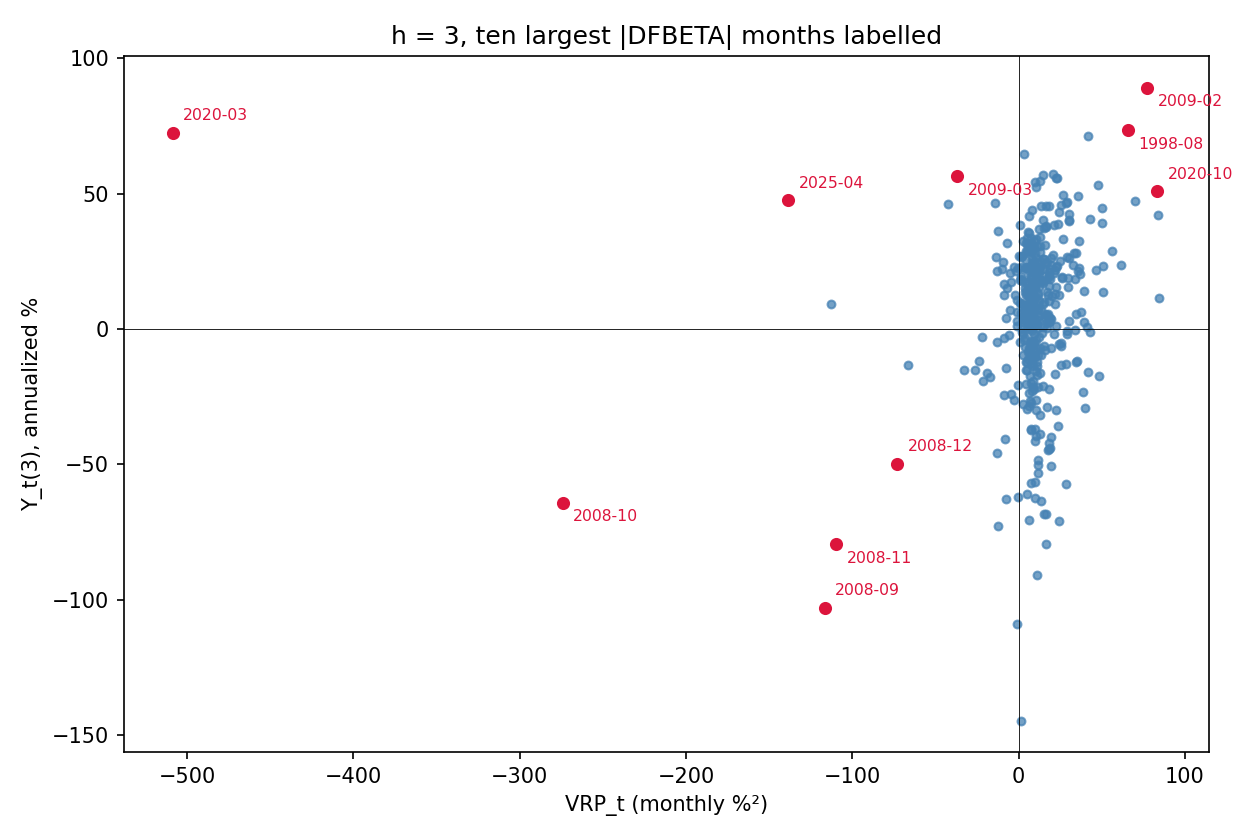

In [15]:
show_figure(RES / "002-influential-obs" / "fig_scatter_h3.png");

*Figure F5.* Three-month average excess return Y_t(3) (annualized %) against VRP_t (monthly %²), 1990–2025; the ten largest |DFBETA| months are labelled. Source: `results/002-influential-obs/fig_scatter_h3.png`, spec 002.

## F6 — A forward-looking premium works where the backward-looking one fails, and not the other way round.

> Replacing last month's realized variance by a real-time forecast (a monthly HAR re-estimated each month on past data only) gives a premium that predicts returns on 2008–2025 (Hodrick t 2.75, adjusted R² about 10%) but not on 1995–2007 (0.87). The original premium does the opposite (1.81 before 2008, 0.92 after). In a joint regression on 1995–2025, only the forecast-based premium is significant (Hodrick t 2.66 against −0.07).

**Source:** spec 003a, commit `ec80a54`; `results/003-inference/table_inference.csv` (rows V-95-07, G-95-07, V-08-25, G-08-25, h = 3), `results/003-inference/table_horse_race.csv` (1995–2025, h = 3), `results/003-inference/fig_subperiod_h3.png`.

In [16]:
g_post = i3.loc["G-08-25"]
check("F6", "Hodrick t, G 2008–2025", g_post["t_1B"], 2.75, 2)
adj_g = adjusted_r2(g_post["R2"], g_post["N"])
print(f"adjusted R², G-08-25, h = 3: {adj_g:.2f}% (R² {g_post['R2']:.2f}%, N {int(g_post['N'])})")
check_that("F6", "adj. R² G 2008–2025 about 10% (9.5–10.6)", 9.5 <= adj_g <= 10.6, f"{adj_g:.2f}%")
check("F6", "Hodrick t, G 1995–2007", i3.loc["G-95-07", "t_1B"], 0.87, 2)
check("F6", "Hodrick t, V 1995–2007", i3.loc["V-95-07", "t_1B"], 1.81, 2)
check("F6", "Hodrick t, V 2008–2025", i3.loc["V-08-25", "t_1B"], 0.92, 2)
check_that(
    "F6", "G significant after 2008 only; V stronger before 2008",
    g_post["t_1B"] > 1.96 and abs(i3.loc["G-95-07", "t_1B"]) < 1.96
    and i3.loc["V-95-07", "t_1B"] > i3.loc["V-08-25", "t_1B"],
    f"G {i3.loc['G-95-07', 't_1B']:.2f} → {g_post['t_1B']:.2f}; "
    f"V {i3.loc['V-95-07', 't_1B']:.2f} → {i3.loc['V-08-25', 't_1B']:.2f}",
)

race = pd.read_csv(RES / "003-inference" / "table_horse_race.csv")
joint = race[(race["sample"] == "1995–2025") & (race["h"] == 3)]
assert len(joint) == 1
joint = joint.iloc[0]
check("F6", "joint Hodrick t, VRP_fwd 1995–2025", joint["t_1B_b2"], 2.66, 2)
check("F6", "joint Hodrick t, VRP 1995–2025", joint["t_1B_b1"], -0.07, 2)
check_that(
    "F6", "only VRP_fwd significant in the joint regression",
    abs(joint["t_1B_b2"]) > 1.96 and abs(joint["t_1B_b1"]) < 1.96,
    f"{joint['t_1B_b2']:.2f} vs {joint['t_1B_b1']:.2f}",
)

pass       F6  Hodrick t, G 2008–2025: claim 2.75, results 2.7513
adjusted R², G-08-25, h = 3: 10.21% (R² 10.63%, N 213)
pass       F6  adj. R² G 2008–2025 about 10% (9.5–10.6): 10.21%
pass       F6  Hodrick t, G 1995–2007: claim 0.87, results 0.8656
pass       F6  Hodrick t, V 1995–2007: claim 1.81, results 1.8133
pass       F6  Hodrick t, V 2008–2025: claim 0.92, results 0.9223
pass       F6  G significant after 2008 only; V stronger before 2008: G 0.87 → 2.75; V 1.81 → 0.92
pass       F6  joint Hodrick t, VRP_fwd 1995–2025: claim 2.66, results 2.6607
pass       F6  joint Hodrick t, VRP 1995–2025: claim -0.07, results -0.0711
pass       F6  only VRP_fwd significant in the joint regression: 2.66 vs -0.07


In [17]:
ids = ["V-95-07", "G-95-07", "V-08-25", "G-08-25", "V-10-25", "G-10-25", "V-10-19", "G-10-19"]
sub = i3.loc[ids, ["coef_B", "t_NW_hm1", "t_1B", "R2", "N"]].reset_index()
sub["adj. R² %"] = adjusted_r2(sub["R2"], sub["N"])
display(styled(sub.rename(columns={"R2": "R² %"}), coef=["coef_B"], ints=["N"]))
display(styled(
    race[race["h"] == 3][["sample", "b1_VRP", "t_1B_b1", "b2_VRP_fwd", "t_1B_b2", "R2", "N", "corr_VRP_VRP_fwd"]]
    .rename(columns={"R2": "R² %"}),
    coef=["b1_VRP", "b2_VRP_fwd"], ints=["N"],
))

id,coef_B,t_NW_hm1,t_1B,R² %,N,adj. R² %
V-95-07,0.373,2.82,1.81,4.24,153,3.61
G-95-07,0.147,0.99,0.87,0.73,153,0.08
V-08-25,0.067,0.51,0.92,1.06,213,0.59
G-08-25,0.393,5.02,2.75,10.63,213,10.21
V-10-25,-0.072,-1.59,-1.12,1.58,189,1.05
G-10-25,0.401,3.01,1.91,5.52,189,5.01
V-10-19,0.166,1.67,1.07,1.65,117,0.79
G-10-19,0.218,1.51,0.86,2.01,117,1.15


sample,b1_VRP,t_1B_b1,b2_VRP_fwd,t_1B_b2,R² %,N,corr_VRP_VRP_fwd
1995–2007,0.454,1.50,-0.122,-0.47,4.55,153,0.63
2008–2025,-0.034,-0.45,0.420,2.82,10.85,213,0.44
1995–2025,-0.005,-0.07,0.330,2.66,5.87,369,0.46


*Tables F6.* Top: h = 3 regressions by sub-period; V = original premium (implied minus last month's realized variance), G = forecast-based premium (implied minus the real-time HAR forecast); coefficient in annualized % per monthly %², R² and adjusted R² in %. Bottom: joint regressions on both premia at h = 3. Source: `results/003-inference/table_inference.csv` and `table_horse_race.csv`, spec 003a.

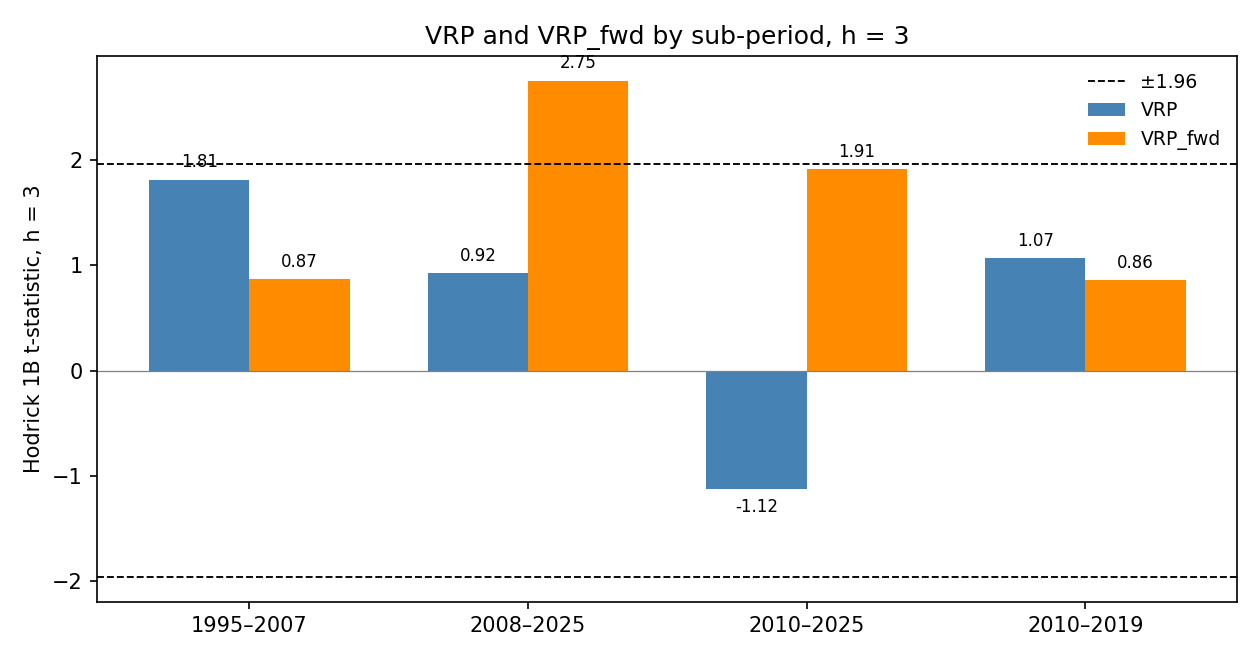

In [18]:
show_figure(RES / "003-inference" / "fig_subperiod_h3.png");

*Figure F6.* Hodrick 1B t-statistic (dimensionless) at h = 3 for the original premium (VRP, blue) and the forecast-based premium (VRP_fwd, orange), by sub-period (horizontal axis: sample years); dashed lines at ±1.96. Source: `results/003-inference/fig_subperiod_h3.png`, spec 003a.

## F7 — There is no predictability in the calm decade.

> On 2010–2019 neither premium predicts returns (Hodrick t 1.07 and 0.86). Predictability is concentrated in stress episodes: the ten largest gaps between the two premia are all crash months (1998-08, 2002-07, 2008-09, 2008-11, 2008-12, 2009-03, 2011-08, 2020-03, 2020-04, 2025-04).

**Source:** spec 003a, commit `ec80a54`; `results/003-inference/table_inference.csv` (rows V-10-19, G-10-19), `results/003-inference/table_mr.csv`; figure from spec 002, commit `18f28d2`, `results/002-influential-obs/fig_rolling_t.png`.

In [19]:
check("F7", "Hodrick t, V 2010–2019", i3.loc["V-10-19", "t_1B"], 1.07, 2)
check("F7", "Hodrick t, G 2010–2019", i3.loc["G-10-19", "t_1B"], 0.86, 2)
check_that(
    "F7", "neither premium significant on 2010–2019",
    (i3.loc[["V-10-19", "G-10-19"], "t_1B"].abs() < 1.96).all(),
    "max |t| " + f"{i3.loc[['V-10-19', 'G-10-19'], 't_1B'].abs().max():.2f}",
)
claimed_dates = {"1998-08", "2002-07", "2008-09", "2008-11", "2008-12",
                 "2009-03", "2011-08", "2020-03", "2020-04", "2025-04"}
check("F7", "number of largest gaps listed", len(top10), 10, 0)
check_that(
    "F7", "top-10 |VRP_fwd − VRP| months equal the listed dates",
    set(top10.index) == claimed_dates, ", ".join(sorted(top10.index)),
)

pass       F7  Hodrick t, V 2010–2019: claim 1.07, results 1.0658
pass       F7  Hodrick t, G 2010–2019: claim 0.86, results 0.8573
pass       F7  neither premium significant on 2010–2019: max |t| 1.07
pass       F7  number of largest gaps listed: claim 10, results 10.00
pass       F7  top-10 |VRP_fwd − VRP| months equal the listed dates: 1998-08, 2002-07, 2008-09, 2008-11, 2008-12, 2009-03, 2011-08, 2020-03, 2020-04, 2025-04


In [20]:
styled(top10[["rank", "MR", "VRP", "VRP_fwd", "RV", "RV_hat"]].reset_index(), ints=["rank"])

date,rank,MR,VRP,VRP_fwd,RV,RV_hat
2020-03,1,536.80,-508.51,28.29,747.39,210.59
2025-04,2,174.38,-138.42,35.96,189.26,14.88
1998-08,3,-119.27,65.70,-53.57,97.69,216.96
2008-12,4,111.64,-72.86,38.79,206.19,94.54
2011-08,5,103.40,-112.53,-9.13,195.85,92.45
2020-04,6,100.00,-42.68,57.32,139.87,39.87
2008-09,7,80.22,-116.50,-36.28,245.80,165.58
2009-03,8,79.87,-36.74,43.13,199.11,119.23
2008-11,9,78.01,-109.55,-31.53,364.20,286.19
2002-07,10,58.38,-66.37,-7.99,151.87,93.48


*Table F7.* The ten months with the largest |MR| = |VRP_fwd − VRP| on 1995–2025, with both premia, realized variance and its real-time forecast, all in monthly %². Source: `results/003-inference/table_mr.csv`, spec 003a.

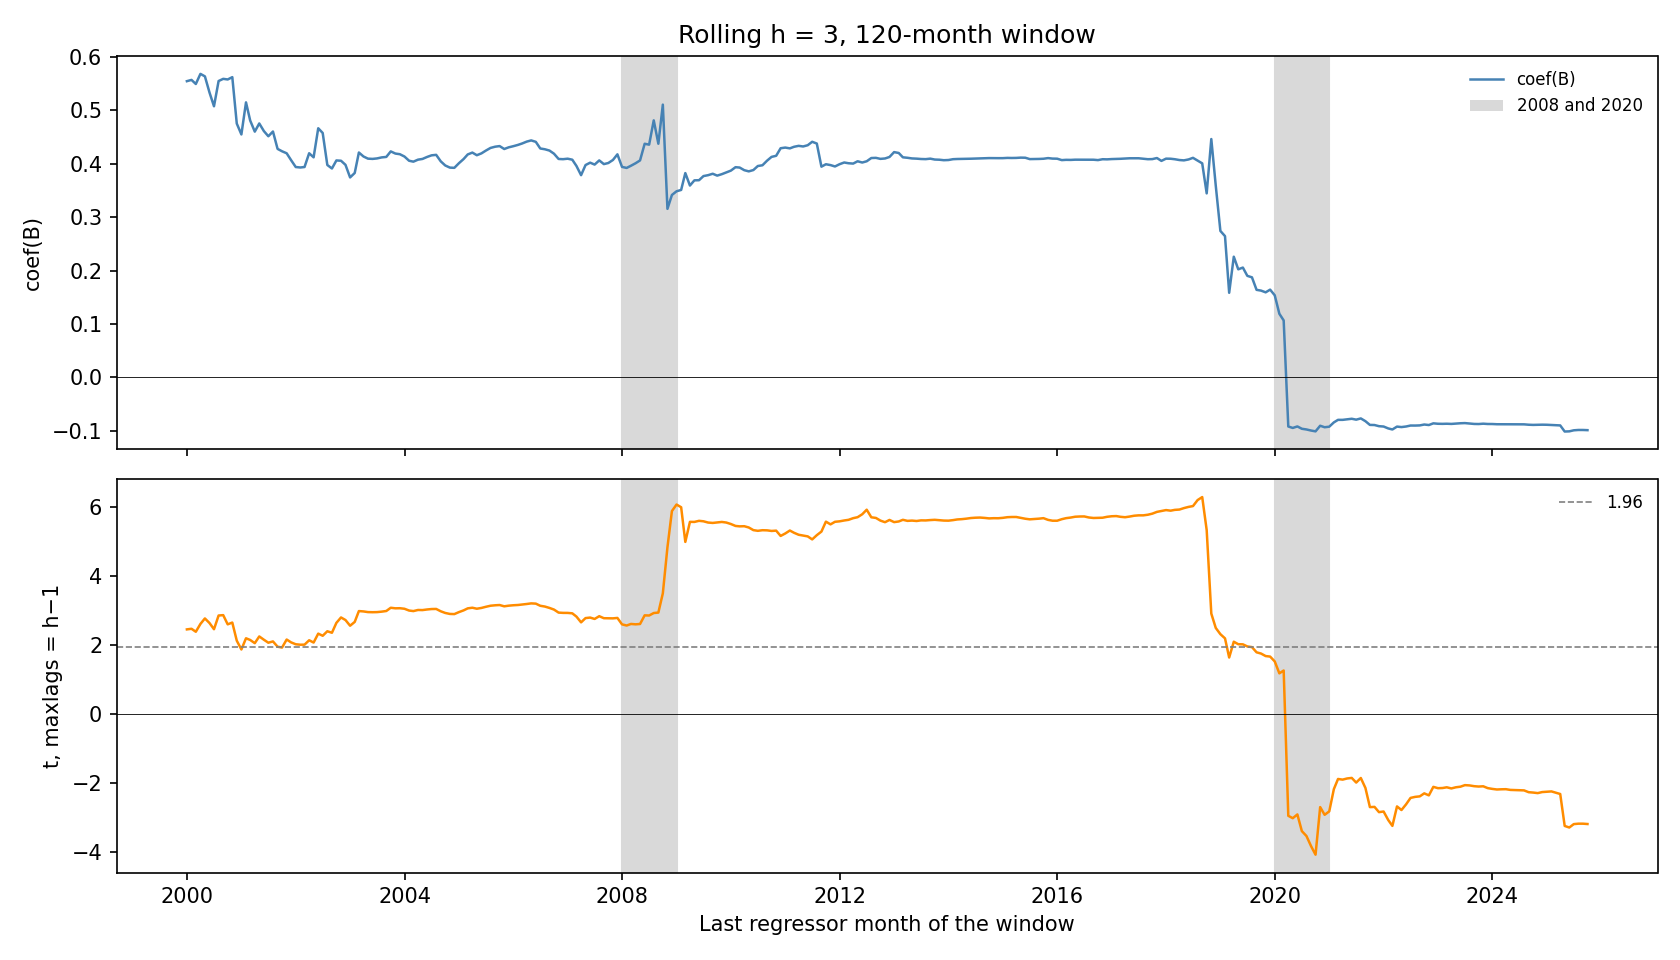

In [21]:
show_figure(RES / "002-influential-obs" / "fig_rolling_t.png");

*Figure F7.* Rolling 120-month regressions at h = 3, plotted against the last regressor month of the window. Top: coefficient (annualized % per monthly %²). Bottom: Newey–West t-statistic (dimensionless, maxlags = h−1), dotted line at 1.96. Shaded: 2008 and 2020. Source: `results/002-influential-obs/fig_rolling_t.png`, spec 002.

## F8 — The premium survives the standard predictors, once they are dated in real time.

> With earnings lagged three months and CAY used only three months after its quarter ends, the variance premium stays significant next to each control on 1990–2007 (Hodrick t from 2.06 with CAY to 2.43 with RREL) and with all five controls together (2.68). Dating the controls as in my first notebook raised the R² of the regressions with log P/E or CAY by 2.3 to 3.0 points and pushed the premium below significance next to CAY (1.92).

**Source:** spec 004, commit `279b701`; `results/004-controls/table4_timing_compare.csv` and `results/004-controls/table4_rt.csv` (block T4-base).

In [22]:
compare = pd.read_csv(RES / "004-controls" / "table4_timing_compare.csv").set_index("regression")
rt = pd.read_csv(RES / "004-controls" / "table4_rt.csv")
t4 = rt[rt["block"] == "T4-base"].set_index("regression")
assert len(t4) == 12 and (t4["N"] == 213).all()
with_vrp = compare.loc[compare["coef_VRP_RT"].notna()].index
assert np.allclose(t4.loc[with_vrp, "t1B_VRP"], compare.loc[with_vrp, "t1B_VRP_RT"], atol=1e-10)

singles = compare[compare["kind"] == "c"]["t1B_VRP_RT"]
check("F8", "Hodrick t VRP, with CAY (RT)", compare.loc["VRP + CAY", "t1B_VRP_RT"], 2.06, 2)
check("F8", "Hodrick t VRP, with RREL (RT)", compare.loc["VRP + RREL", "t1B_VRP_RT"], 2.43, 2)
check_that(
    "F8", "VRP significant next to each control; range runs from CAY to RREL",
    (singles > 1.96).all() and singles.idxmin() == "VRP + CAY" and singles.idxmax() == "VRP + RREL",
    ", ".join(f"{k.replace('VRP + ', '')} {v:.2f}" for k, v in singles.items()),
)
controls = ["log_PE", "DFSP", "TMSP", "RREL", "CAY"]
check("F8", "controls in the joint regression", t4.loc["VRP + all", [f"coef_{c}" for c in controls]].notna().sum(), 5, 0)
check("F8", "Hodrick t VRP, all controls (RT)", compare.loc["VRP + all", "t1B_VRP_RT"], 2.68, 2)

lift = compare.loc[["VRP + log_PE", "VRP + CAY"], "R2_NB_minus_RT"]
check("F8", "smallest R² increase, VRP + log P/E or CAY (points)", lift.min(), 2.3, 1)
check("F8", "largest R² increase, VRP + log P/E or CAY (points)", lift.max(), 3.0, 1)
check("F8", "Hodrick t VRP, with CAY (first-notebook dating)", compare.loc["VRP + CAY", "t1B_VRP_NB"], 1.92, 2)
check_that(
    "F8", "first-notebook dating pushes VRP below 1.96 next to CAY",
    compare.loc["VRP + CAY", "t1B_VRP_NB"] < 1.96, f"{compare.loc['VRP + CAY', 't1B_VRP_NB']:.3f}",
)

pass       F8  Hodrick t VRP, with CAY (RT): claim 2.06, results 2.0598
pass       F8  Hodrick t VRP, with RREL (RT): claim 2.43, results 2.4309
pass       F8  VRP significant next to each control; range runs from CAY to RREL: log_PE 2.40, DFSP 2.23, TMSP 2.25, RREL 2.43, CAY 2.06
pass       F8  controls in the joint regression: claim 5, results 5.00
pass       F8  Hodrick t VRP, all controls (RT): claim 2.68, results 2.6774
pass       F8  smallest R² increase, VRP + log P/E or CAY (points): claim 2.3, results 2.331
pass       F8  largest R² increase, VRP + log P/E or CAY (points): claim 3.0, results 2.981
pass       F8  Hodrick t VRP, with CAY (first-notebook dating): claim 1.92, results 1.9184
pass       F8  first-notebook dating pushes VRP below 1.96 next to CAY: 1.918


In [23]:
coef_cols = ["coef_VRP"] + [f"coef_{c}" for c in controls]
t_cols = ["t1B_VRP"] + [f"t1B_{c}" for c in controls]
display(styled(t4.reset_index()[["regression"] + [c for pair in zip(coef_cols, t_cols) for c in pair] + ["R2", "N"]],
               coef=coef_cols, ints=["N"]))
display(styled(
    compare.reset_index()[["regression", "R2_RT", "R2_NB", "R2_NB_minus_RT", "t1B_VRP_RT", "t1B_VRP_NB", "N"]],
    ints=["N"],
))

regression,coef_VRP,t1B_VRP,coef_log_PE,t1B_log_PE,coef_DFSP,t1B_DFSP,coef_TMSP,t1B_TMSP,coef_RREL,t1B_RREL,coef_CAY,t1B_CAY,R2,N
VRP,0.420,2.22,—,—,—,—,—,—,—,—,—,—,4.98,213
log_PE,—,—,-26.063,-1.77,—,—,—,—,—,—,—,—,6.51,213
DFSP,—,—,—,—,-16.734,-0.90,—,—,—,—,—,—,1.66,213
TMSP,—,—,—,—,—,—,-0.684,-0.26,—,—,—,—,0.09,213
RREL,—,—,—,—,—,—,—,—,3.893,0.92,—,—,0.97,213
CAY,—,—,—,—,—,—,—,—,—,—,323.965,1.25,1.63,213
VRP + log_PE,0.480,2.40,-29.029,-1.91,—,—,—,—,—,—,—,—,12.95,213
VRP + DFSP,0.417,2.23,—,—,-16.392,-0.88,—,—,—,—,—,—,6.57,213
VRP + TMSP,0.418,2.25,—,—,—,—,-0.362,-0.14,—,—,—,—,5.01,213
VRP + RREL,0.469,2.43,—,—,—,—,—,—,5.706,1.33,—,—,6.99,213


regression,R2_RT,R2_NB,R2_NB_minus_RT,t1B_VRP_RT,t1B_VRP_NB,N
VRP,4.98,4.98,0.00,2.22,2.22,213
log_PE,6.51,8.47,1.96,—,—,213
DFSP,1.66,1.66,0.00,—,—,213
TMSP,0.09,0.09,0.00,—,—,213
RREL,0.97,0.97,0.00,—,—,213
CAY,1.63,4.52,2.89,—,—,213
VRP + log_PE,12.95,15.93,2.98,2.40,2.59,213
VRP + DFSP,6.57,6.57,0.00,2.23,2.23,213
VRP + TMSP,5.01,5.01,0.00,2.25,2.25,213
VRP + RREL,6.99,6.99,0.00,2.43,2.43,213


*Tables F8.* Top: Table 4 on 1990–2007 at h = 3 with real-time controls (block T4-base): coefficients and Hodrick 1B t-statistics, R² in %. VRP in monthly %²; the controls in their spec 004 units. Bottom: R² (%) and the VRP Hodrick t under real-time dating (RT) and under the first notebook's dating (NB). Sources: `results/004-controls/table4_rt.csv` and `table4_timing_compare.csv`, spec 004.

## F9 — The European extension holds only after 2008.

> Starting European returns at the first close after the US premium is known, the US premium does not predict DAX or CAC returns before 2008 (Hodrick t 1.14 and 1.10), although the Newey–West t-statistics are above 2. After 2008 the forecast-based US premium predicts both (2.19 and 2.46). The timing correction changes t by less than 0.3, except for the CAC after 2008 (0.43). The DAX is less correlated with the US premium than the US market itself (0.14 vs 0.20).

**Source:** spec 005, commit `efef1c3`; `results/005-europe/table_europe.csv` and `results/005-europe/table_timing.csv` (h = 3, SK timing), `results/005-europe/fig_europe_h3.png`.

In [24]:
europe = pd.read_csv(RES / "005-europe" / "table_europe.csv")
e3 = europe[europe["h"] == 3]


def eu(market, regressor, timing, sample):
    row = e3[(e3["market"] == market) & (e3["regressor"] == regressor)
             & (e3["timing"] == timing) & (e3["sample"] == sample)]
    assert len(row) == 1, (market, regressor, timing, sample)
    return row.iloc[0]


dax_pre, cac_pre = eu("DAX", "VRP", "SK", "pre-2008"), eu("CAC", "VRP", "SK", "pre-2008")
check("F9", "Hodrick t, DAX pre-2008 (SK)", dax_pre["t_1B"], 1.14, 2)
check("F9", "Hodrick t, CAC pre-2008 (SK)", cac_pre["t_1B"], 1.10, 2)
check_that(
    "F9", "NW t above 2 for both before 2008",
    dax_pre["t_NW_hm1"] > 2 and cac_pre["t_NW_hm1"] > 2,
    f"DAX {dax_pre['t_NW_hm1']:.2f}, CAC {cac_pre['t_NW_hm1']:.2f}",
)
check("F9", "Hodrick t, DAX post-2008 VRP_fwd (SK)", eu("DAX", "VRP_fwd", "SK", "post-2008")["t_1B"], 2.19, 2)
check("F9", "Hodrick t, CAC post-2008 VRP_fwd (SK)", eu("CAC", "VRP_fwd", "SK", "post-2008")["t_1B"], 2.46, 2)

shifts = {}
for market in ("DAX", "CAC"):
    for regressor in ("VRP", "VRP_fwd"):
        for sample in ("pre-2008", "post-2008"):
            shifts[(market, regressor, sample)] = abs(
                eu(market, regressor, "SK", sample)["t_1B"] - eu(market, regressor, "NB", sample)["t_1B"]
            )
timing = pd.read_csv(RES / "005-europe" / "table_timing.csv").set_index(["market", "sample"])
for (market, sample), row in timing.iterrows():
    assert abs(abs(row["t1B_SK_minus_NB"]) - shifts[(market, "VRP", sample)]) < 1e-10
others = {k: v for k, v in shifts.items() if k != ("CAC", "VRP", "post-2008")}
check_that(
    "F9", "timing shift of Hodrick t below 0.3 except CAC post-2008",
    max(others.values()) < 0.3, f"largest other shift {max(others.values()):.3f}",
)
check("F9", "timing shift, CAC post-2008", shifts[("CAC", "VRP", "post-2008")], 0.43, 2)

us_pre = eu("US", "VRP", "spec001", "pre-2008")
check("F9", "correlation US VRP with DAX return (std coef)", dax_pre["std_coef"], 0.14, 2)
check("F9", "correlation US VRP with US return (std coef)", us_pre["std_coef"], 0.20, 2)
check_that("F9", "DAX correlation below the US one", dax_pre["std_coef"] < us_pre["std_coef"],
           f"{dax_pre['std_coef']:.3f} vs {us_pre['std_coef']:.3f}")

pass       F9  Hodrick t, DAX pre-2008 (SK): claim 1.14, results 1.1364


pass       F9  Hodrick t, CAC pre-2008 (SK): claim 1.1, results 1.0959
pass       F9  NW t above 2 for both before 2008: DAX 2.53, CAC 2.09
pass       F9  Hodrick t, DAX post-2008 VRP_fwd (SK): claim 2.19, results 2.1885
pass       F9  Hodrick t, CAC post-2008 VRP_fwd (SK): claim 2.46, results 2.4580


pass       F9  timing shift of Hodrick t below 0.3 except CAC post-2008: largest other shift 0.253
pass       F9  timing shift, CAC post-2008: claim 0.43, results 0.4304
pass       F9  correlation US VRP with DAX return (std coef): claim 0.14, results 0.1424
pass       F9  correlation US VRP with US return (std coef): claim 0.2, results 0.2036
pass       F9  DAX correlation below the US one: 0.142 vs 0.204


In [25]:
cols = ["market", "regressor", "timing", "sample", "start", "end", "coef_B", "t_NW_hm1", "t_1B", "std_coef", "R2", "N"]
styled(e3[cols].sort_values(["sample", "regressor", "market", "timing"], ascending=[False, True, True, True]),
       coef=["coef_B", "std_coef"], ints=["N"])

market,regressor,timing,sample,start,end,coef_B,t_NW_hm1,t_1B,std_coef,R2,N
CAC,VRP,NB,pre-2008,1994-02,2007-12,0.370,2.35,1.19,0.142,2.02,164
CAC,VRP,SK,pre-2008,1994-02,2007-12,0.340,2.09,1.10,0.131,1.73,164
CAC,VRP,T-1,pre-2008,1994-02,2007-12,0.364,2.23,1.18,0.141,1.99,164
DAX,VRP,NB,pre-2008,1994-02,2007-12,0.473,2.64,1.25,0.154,2.36,164
DAX,VRP,SK,pre-2008,1994-02,2007-12,0.434,2.53,1.14,0.142,2.03,164
DAX,VRP,T-1,pre-2008,1994-02,2007-12,0.455,2.49,1.25,0.150,2.24,164
US,VRP,spec001,pre-2008,1994-02,2007-12,0.370,2.80,1.80,0.204,4.15,164
CAC,VRP_fwd,NB,pre-2008,1995-01,2007-12,0.297,1.57,1.28,0.122,1.50,153
CAC,VRP_fwd,SK,pre-2008,1995-01,2007-12,0.296,1.48,1.32,0.123,1.50,153
DAX,VRP_fwd,NB,pre-2008,1995-01,2007-12,0.166,0.85,0.59,0.057,0.32,153


*Table F9.* US premium predicting US, DAX and CAC excess returns at h = 3. Timing: NB = European return from the close of the US premium's last day (first notebook), SK = from the first European close after the premium is known, T−1 = premium dated one day earlier. Coefficient in annualized % per monthly %²; std coef = coef × sd(VRP)/sd(Y), the correlation of the premium with the future return; R² in %. Source: `results/005-europe/table_europe.csv`, spec 005.

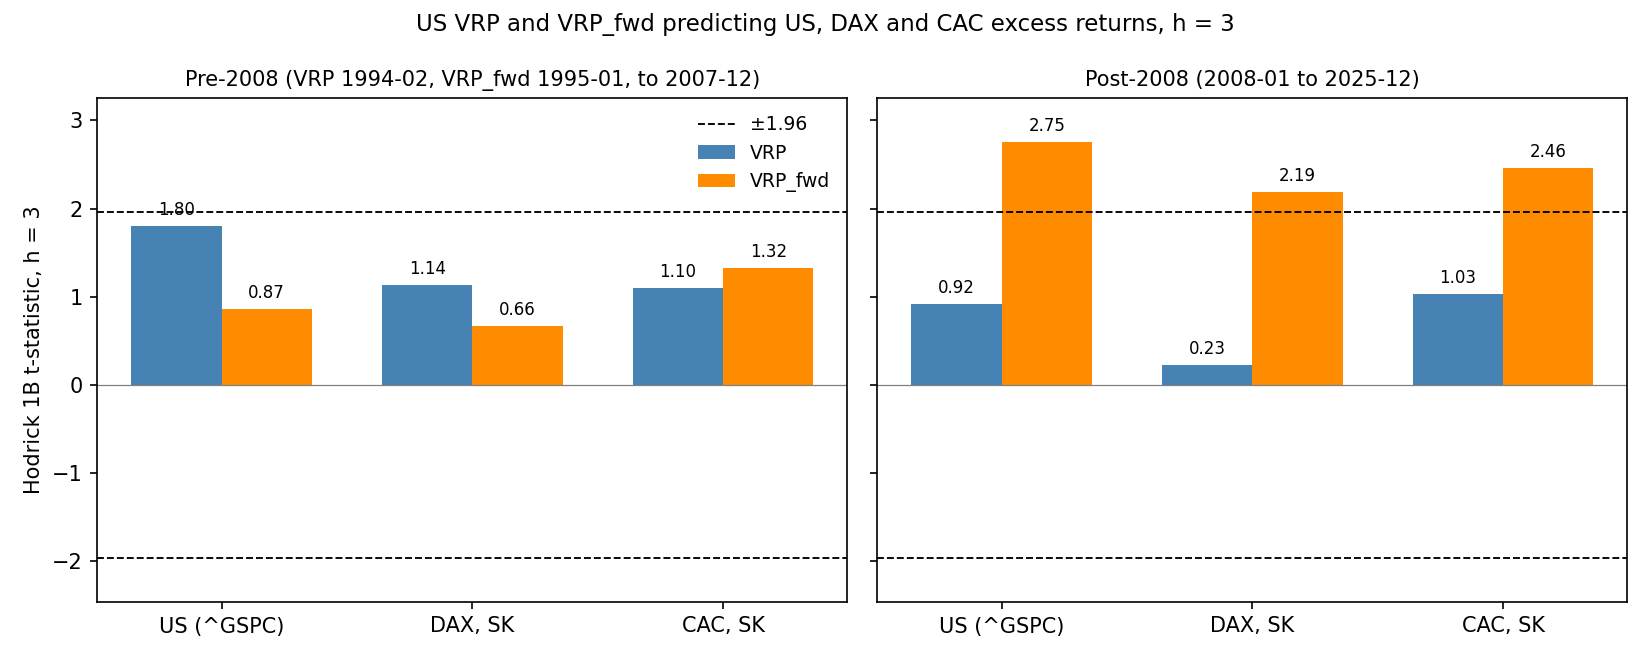

In [26]:
show_figure(RES / "005-europe" / "fig_europe_h3.png");

*Figure F9.* Hodrick 1B t-statistic (dimensionless) at h = 3 for the US premium (VRP, blue) and the forecast-based premium (VRP_fwd, orange) predicting US, DAX and CAC returns (SK timing for Europe), before and after 2008; dashed lines at ±1.96. Source: `results/005-europe/fig_europe_h3.png`, spec 005.

## F10 — What changed from my first notebook

| v1 notebook | Problem | Corrected |
|---|---|---|
| Coefficients compared with BTZ (2.32 vs 0.47) | different units | 0.42 vs 0.47 |
| Sample 1993–2007, SPY | not the paper's sample | 1990–2007, ^GSPC |
| Risk-free rate of month t | monthly average, unknown at the start of t | rate of t−1 |
| Newey–West t only | oversized (8–13% for a 5% test) | Hodrick 1B (the paper's choice) and null bootstrap |
| "Works in growth, not in crises" | one month drives it (March 2020, Cook's D 15.9); premium mismeasured after V-shaped crashes | the forecast-based premium predicts on 2008–2025 |
| CAY and Shiller earnings used at t | publication lags: look-ahead | control R² inflated by 2.3–3.0 points; premium + CAY was not significant (1.92 instead of 2.06) |
| European return from the close of the last day | starts 4h30 before the premium is observable | skip day 1; effect below 0.3 of t except CAC post-2008 (0.43) |
| "The DAX is more sensitive" | raw slopes across markets of different volatility | the DAX correlation is lower than the US one |
| Dividend note | reversed (SPY adjusted, ^GSPC and ^FCHI price, ^GDAXI total return); a constant yield moves the intercept, not the slope | corrected |
| "US premium predicts DAX and CAC, 1994–2007" | does not survive Hodrick (about 1.1) | withdrawn; holds after 2008 with the forecast-based premium |
| Minor | "Shiller CAPE" (it is a trailing P/E), "Adjusted R²" axis label (it was plain R²), 52/395 negative months (53/396 in the output) | corrected |

## Open questions

- Out of sample: does the forecast-based premium beat the historical mean (Campbell–Thompson R²) after 2008, in real time?
- International evidence: compare with Bollerslev, Marrone, Xu & Zhou (2014), who study variance premia across countries.
- A local European premium (VSTOXX or VDAX) instead of the US VIX.
- Daily horizon: the next-day DAX effect needs the open-to-open test before it can be stated.

## Run log

Every assertion above, with the value the results give. `DEVIATION` marks a claim number that the results do not reproduce; the claim text is kept as written and the deviation is explained in `results/006-findings/SUMMARY.md`.

In [27]:
DEVIATION_NOTES = {
    ("F2", "t1B ratio, h = 6"): (
        "The ratio is 1.8556 / 2.15 = 0.863. The claim's 0.87 is 1.86 / 2.15, i.e. the ratio of the rounded quick-check t."
    ),
    ("F2", "sqrt adj. R² ratio, h = 1"): (
        "√(0.8956 / 1.07) = 0.915. The claim's 0.92 is √(0.90 / 1.07), computed on the rounded adjusted R²."
    ),
    ("F2", "sqrt adj. R² ratio, h = 3"): (
        "√(4.5291 / 6.82) = 0.8149. The claim's 0.82 is √(4.53 / 6.82) = 0.8150, computed on the rounded adjusted R²."
    ),
    ("F2", "daily returns a month"): (
        f"`data/gspc_data.csv` has {per_month.mean():.2f} daily returns per month on average over 1990-01 – 2007-12 "
        f"(min {per_month.min()}, max {per_month.max()}), not 22. This number is not in any results file; "
        "it is counted from the frozen price data."
    ),
    ("F2", "five-minute returns a month"): (
        f"78 five-minute returns a day (6.5 trading hours) × {per_month.mean():.2f} days = {78 * per_month.mean():,.0f}, "
        "which rounds to 1,600, not \"about 1,700\". "
        "With 22 days it would be 1,716. The deviation follows from the previous one."
    ),
}
OTHER_NOTES = [
    "F1: the spec writes the coefficient assertion as max |coef − BTZ| ≤ 0.05 for h ≤ 15. The largest gap is "
    f"{gap_15.max():.4f}, at h = {gap_15.idxmax()} (0.4196 vs 0.47), so the strict inequality fails by "
    f"{gap_15.max() - 0.05:.4f}. The notebook asserts it at the general tolerance (0.05 ± 0.005), which passes; "
    "on the coefficients rounded to two decimals, as in the claim (0.42 vs 0.47), the gap is exactly 0.05.",
    "F8: \"raised the R² of the regressions with log P/E or CAY by 2.3 to 3.0 points\" is asserted on the two regressions "
    f"of the premium with log P/E and with CAY (+{lift['VRP + log_PE']:.2f} and +{lift['VRP + CAY']:.2f}). "
    "The univariate regressions move by "
    f"{compare.loc['log_PE', 'R2_NB_minus_RT']:.2f} (log P/E) and {compare.loc['CAY', 'R2_NB_minus_RT']:.2f} (CAY), and the "
    f"regression with all five controls by {compare.loc['VRP + all', 'R2_NB_minus_RT']:.2f}; the univariate log P/E and the "
    "all-controls figures fall outside 2.3–3.0. The claim should say which regressions it means.",
    "F4: `fig_boot_h3.png` was copied as required. It predates spec 003a and shows the iid and stationary-block schemes; "
    "the wild bootstrap quoted in the claim has no histogram.",
    "Formatting: p-values are shown to 3 decimals, not 2, so that the claim's 0.002 and 0.007 are visible in the table; "
    "bootstrap sizes are shown in percent.",
    "Copied figures keep the labels of the spec that drew them. Where an axis has no unit (rolling coefficient in "
    "`fig_rolling_t.png`, sub-period axis in `fig_subperiod_h3.png`, t-statistics everywhere), the unit is given in the caption cell.",
]

log = pd.DataFrame(ASSERTIONS)
log.to_csv(OUT / "assertions.csv", index=False)
runtime = time.perf_counter() - T0
n_dev = int((log["status"] == "DEVIATION").sum())
assert set(log.loc[log["status"] == "DEVIATION", ["finding", "assertion"]].itertuples(index=False, name=None)) == set(KNOWN_DEVIATIONS)
assert runtime < 120, f"Run took {runtime:.1f} s"

lines = [
    "# Spec 006 Part B — findings notebook",
    "",
    "Written by the last cell of `findings.ipynb`. The notebook reads `results/*/` and does not re-estimate anything; "
    "the one exception is the count of trading days per month in F2, read from `data/gspc_data.csv`.",
    "",
    f"- Assertions: {len(log)}, of which {len(log) - n_dev} pass and {n_dev} are recorded deviations.",
    f"- Runtime of Restart & Run All, inside the kernel: {runtime:.1f} s (limit 120 s).",
    "- Figures in this folder: " + ", ".join(sorted(f"`{p.name}`" for p in OUT.glob("*.png"))) + ".",
    "- `findings.html` is exported with `jupyter nbconvert --to html --execute findings.ipynb`.",
    "",
    "## Assertions",
    "",
    "Numbers are asserted to ±0.5 in the last digit printed in the claim. \"holds\" rows assert a qualitative statement; "
    "the results column lists the values behind it.",
    "",
    "| finding | assertion | claim | results | status |",
    "|---|---|---|---|---|",
]
def cell(text):
    return str(text).replace("|", "\\|")


lines += [
    f"| {r.finding} | {cell(r.assertion)} | {cell(r.claim)} | {cell(r.results)} | {r.status} |"
    for r in log.itertuples()
]
lines += ["", "## Deviations", "", "Claim numbers that the results do not reproduce. The claim texts were not changed.", ""]
for i, (key, text) in enumerate(DEVIATION_NOTES.items(), start=1):
    row = log[(log["finding"] == key[0]) & (log["assertion"] == key[1])].iloc[0]
    lines.append(f"{i}. **{key[0]}, {key[1]}**: claim {row['claim']}, results {row['results']}. {text}")
lines += ["", "## Other notes", ""]
lines += [f"- {text}" for text in OTHER_NOTES]
(OUT / "SUMMARY.md").write_text("\n".join(lines) + "\n", encoding="utf-8")

print(f"{len(log)} assertions, {n_dev} deviations, {runtime:.1f} s")
styled(log)

71 assertions, 5 deviations, 0.4 s


finding,assertion,claim,results,status
F1,max |coef − BTZ| ≤ 0.05 for h ≤ 15 (±0.005),holds,max 0.0504 at h = 3,pass
F1,"coef, h = 3",0.42,0.4196,pass
F1,"BTZ coef, h = 3",0.47,0.4700,pass
F1,coefficient peaks at h = 3 (mine and BTZ),holds,"argmax mine h = 3, BTZ h = 3",pass
F1,Hodrick t peaks at h = 3 (mine and BTZ),holds,"argmax mine h = 3, BTZ h = 3",pass
F1,"Hodrick t, h = 3",2.22,2.2185,pass
F1,"BTZ Hodrick t, h = 3",2.86,2.8600,pass
F1,no Hodrick |t| above 1.96 for h ≥ 18 (mine and BTZ),holds,"mine 0.86, 0.56; BTZ 0.56, 0.11",pass
F2,"t1B ratio, h = 1",0.82,0.8196,pass
F2,"t1B ratio, h = 3",0.78,0.7757,pass
